# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"


## Índice
1. **Carga del conjunto de datos.**
2. **Inspección y análisis del conjunto de datos.**
3. **Acondicionamiento y preprocesamiento de los datos.**
4. **Estrategia 1: entrenamiento desde cero (*from scratch*).**

    4.1. Carga de los datos.

    4.2. Diseño de la arquitectura.

    4.3. Entrenamiento del modelo base.

    4.4. Mejora con *data augmentation* y *weight decay*.

    4.5. Evaluación en test.

    4.6. Conclusiones de la Estrategia 1.

5. **Estrategia 2: redes preentrenadas (*transfer learning* y *fine-tuning*).**

   5.1. Carga de los datos.

   5.2. Extracción de características: comparación de arquitecturas.

   5.3. Comprobación del preprocesado.

   5.4. Ajuste del clasificador.

   5.5. Fine-tuning.

   5.6. Evaluación en test.

   5.7. Conclusiones de la Estrategia 2.
   
6. **Comparación de las estrategias y conclusiones.**

## 1. Carga del conjunto de datos

Desde Kaggle, obtenemos el dataset Stanford Dogs para clasificación. Para descargarlo usamos `kagglehub` que descarga y descomprime el dataset automáticamente. 

In [1]:
import kagglehub

path = kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset")
print("Path to dataset files:", path)

ModuleNotFoundError: No module named 'kagglehub'

En la sección 3 del índice se implementará una función reutilizable que automatice la descarga, acondicionamiento y preprocesamiento del conjunto de datos. 

## 2. Inspección y análisis del conjunto de datos

Primeramente, fijar la semilla para reproducibilidad y librerías en esta sección.

In [3]:
import random
import numpy as np
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

import os
import matplotlib.pyplot as plt
import cv2
from PIL import Image

Para justificar la elección del dataset de imágenes para clasificación, describimos las características principales del dataset.  Una vez descargado, vemos cómo están organizados los archivos. Se tienen dos carpetas `annotations` y `images`. La carpeta `images` contiene una subcarpeta por cada raza de perro. En total hay 120 razas de perro.

In [4]:
print(os.listdir(path))

['annotations', 'images']


In [5]:
img_dir_path = os.path.join(path, "images")
print(os.listdir(img_dir_path))

['Images']


In [6]:
img_dir = os.path.join(img_dir_path, "Images")
print(os.listdir(img_dir)[:5])
total_razas = sorted(os.listdir(img_dir))
print("Número de carpetas:", len(total_razas))

['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']
Número de carpetas: 120


Al acceder al contenido de una carpeta, una raza, vemos que se encuentran las imágenes de cada una en formato `.jpg`. A continuación, una muestra de las imágenes de varias razas.  

['n02085620_10074.jpg', 'n02085620_10131.jpg', 'n02085620_10621.jpg', 'n02085620_1073.jpg', 'n02085620_10976.jpg']


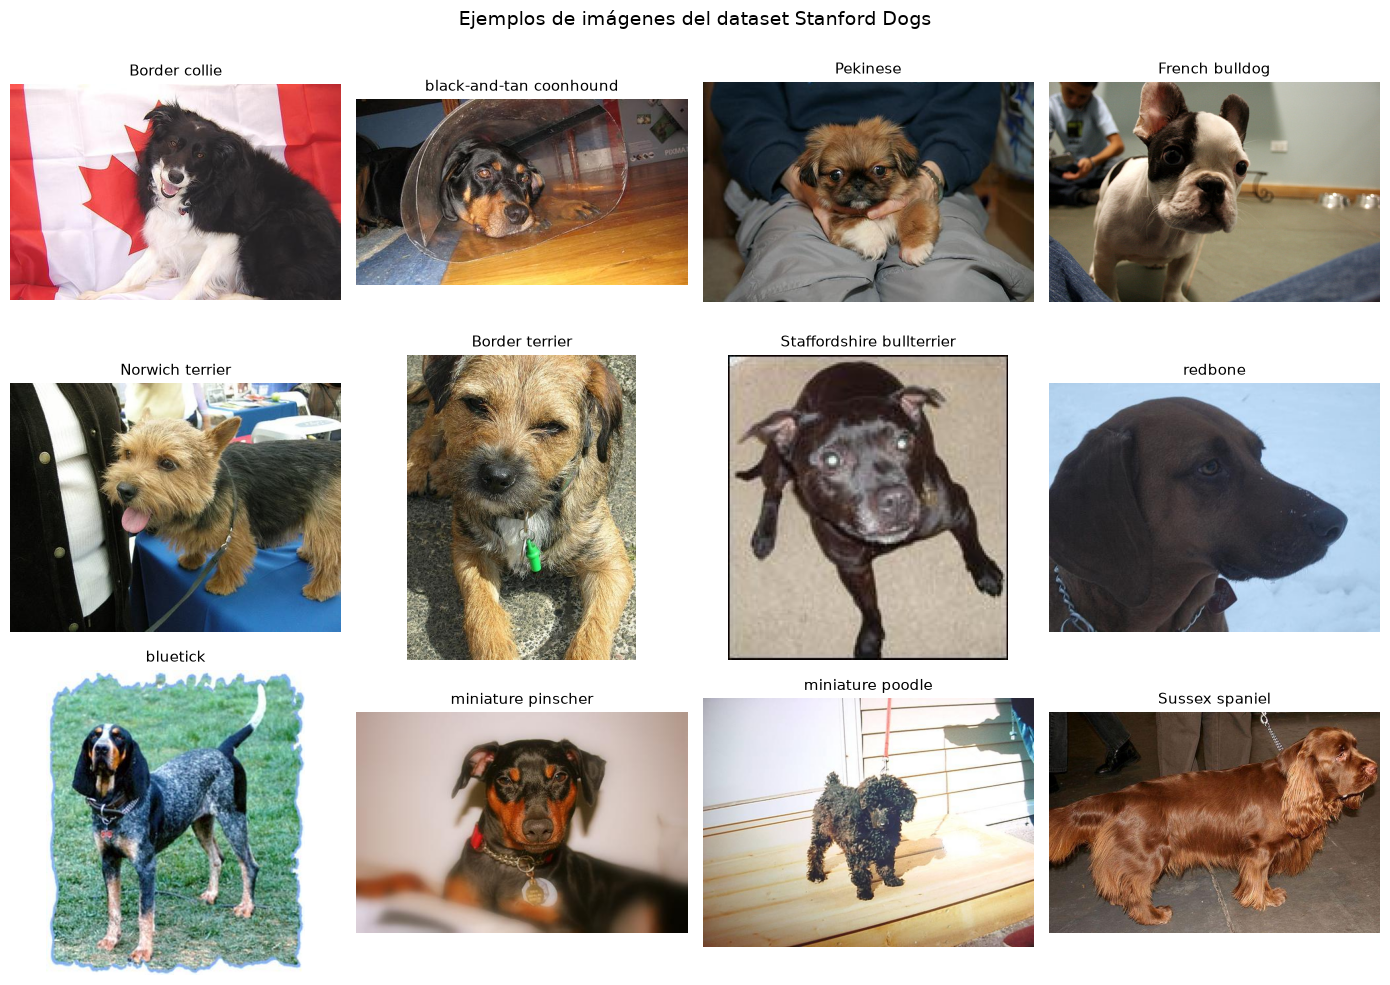

In [7]:
print(os.listdir(os.path.join(img_dir, "n02085620-Chihuahua"))[:5])

random.seed(SEED)
razas_muestra = random.sample(total_razas, 12)   # 12 razas distintas al azar

def nombre_raza(ruta):
    """De '.../n02085620-Chihuahua/foto.jpg' a 'Chihuahua'."""
    return os.path.basename(os.path.dirname(ruta)).split("-", 1)[1].replace("_", " ")

def mostrar_cuadricula(rutas_img, titulos, titulo_general, filas=3, columnas=4):
    fig, axes = plt.subplots(filas, columnas, figsize=(14, 10))
    for ax, ruta, titulo in zip(axes.flat, rutas_img, titulos):
        ax.imshow(Image.open(ruta))
        ax.set_title(titulo, fontsize=11)
        ax.axis("off")
    plt.suptitle(titulo_general, fontsize=14)
    plt.tight_layout()
    plt.show()

rutas_img = [os.path.join(img_dir, c, random.choice(os.listdir(os.path.join(img_dir, c))))
             for c in razas_muestra]

mostrar_cuadricula(rutas_img, [nombre_raza(r) for r in rutas_img],
                   "Ejemplos de imágenes del dataset Stanford Dogs")

Veamos cuántas imágenes hay en cada carpeta por raza, es decir, por clase. Con ello también se obtiene el número total de imágenes del dataset, el mínimo número de imágenes por raza, el máximo y la media. Representamos la distribución de las clases en un gráfico de barras ordenado de mayor a menor, con una línea horizontal en la media y así comprobar si el dataset está equilibrado.

Número total de imágenes: 20580
Imágenes por raza con mínimo: 148 , máximo: 252 , media: 171.5


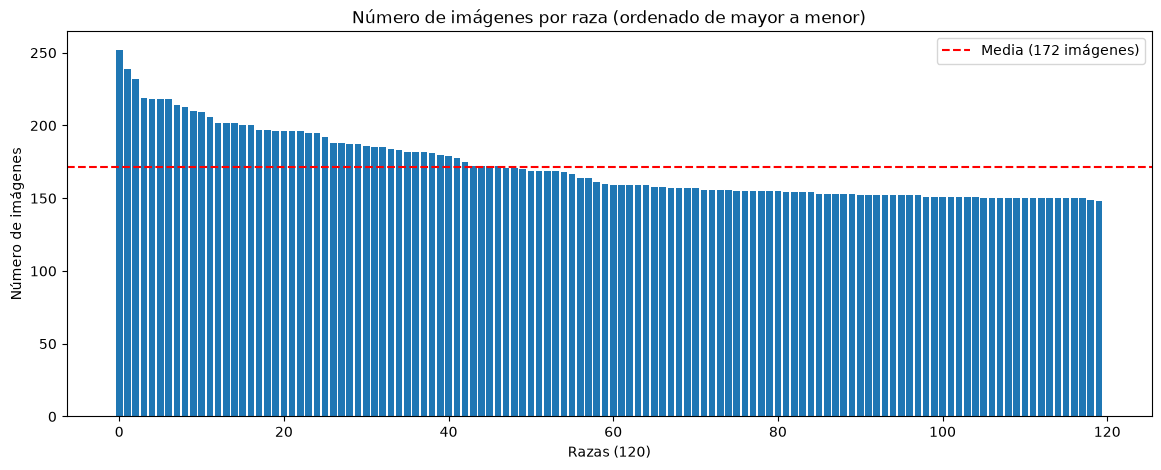

In [8]:
conteo_por_raza = []
for r in total_razas:
    a = len(os.listdir(os.path.join(img_dir, r)))
    conteo_por_raza.append(a)
total_imagenes = sum(conteo_por_raza)
media = total_imagenes / len(total_razas)
print("Número total de imágenes:", total_imagenes)
print("Imágenes por raza con mínimo:", min(conteo_por_raza), ", máximo:", max(conteo_por_raza), ", media:", media)
conteo_ordenado = sorted(conteo_por_raza, reverse=True)

plt.figure(figsize=(14, 5))
plt.bar(range(len(conteo_ordenado)), conteo_ordenado)
plt.axhline(media, color="red", linestyle="--", label=f"Media ({media:.0f} imágenes)")
plt.title("Número de imágenes por raza (ordenado de mayor a menor)")
plt.xlabel("Razas (120)")
plt.ylabel("Número de imágenes")
plt.legend()
plt.show()

El número de imágenes por raza va de 148 a 252, con una media de unas 171. Aunque la clase más grande tiene unas 252/148 $\approx$ 1,7 veces más imágenes que la más pequeña, ninguna raza está claramente infrarrepresentada, así que el dataset está razonablemente equilibrado. Por eso usaremos la accuracy como métrica principal, sin ponderar las clases.

Esto también nos da una referencia mínima para los modelos. Un clasificador aleatorio acertaría 1/120 $\approx$ 0,8 % de las veces, y un clasificador trivial que siempre predijera la raza más frecuente acertaría 252/20580 $\approx$ 1,2 %. Cualquier modelo que haya aprendido algo de los datos debe superar estos valores.

Vemos también las dimensiones de las imágenes. Para ello leemos el ancho y el alto de cada una (con PIL) y los representamos en un mapa de calor, donde las zonas más intensas indican los tamaños más frecuentes.

Hay 4542 tamaños distintos
Ancho: mínimo 97 , máximo 3264 , mediana 500
Alto:  mínimo 100 , máximo 2562 , mediana 375
Tamaño más frecuente: 500x375 (5301 imágenes, 25.8% del total)
Tamaños distintos en Chihuahua: 81


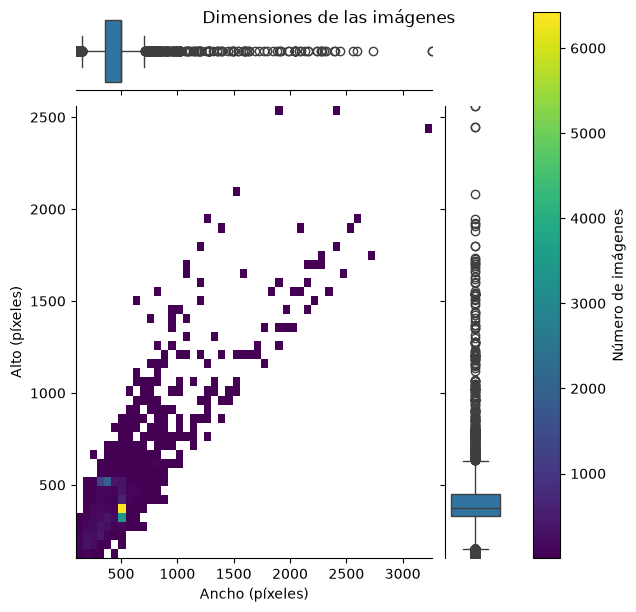

In [9]:
from glob import glob
from collections import Counter
from PIL import Image
import seaborn as sns

rutas = glob(os.path.join(img_dir, "*", "*.jpg"))
tamanos = [Image.open(r).size for r in rutas]
anchos, altos = zip(*tamanos)
tamanos_distintos = Counter(tamanos)

(w, h), n = tamanos_distintos.most_common(1)[0]

print("Hay", len(tamanos_distintos), "tamaños distintos")
print("Ancho: mínimo", min(anchos), ", máximo", max(anchos), ", mediana", int(np.median(anchos)))
print("Alto:  mínimo", min(altos),  ", máximo", max(altos),  ", mediana", int(np.median(altos)))
print(f"Tamaño más frecuente: {w}x{h} ({n} imágenes, {n / len(tamanos):.1%} del total)")

chihuahua = Counter(t for r, t in zip(rutas, tamanos) if "Chihuahua" in r)
print("Tamaños distintos en Chihuahua:", len(chihuahua))

g = sns.JointGrid(x=np.array(anchos), y=np.array(altos), height=6)
mapa = g.ax_joint.hist2d(anchos, altos, bins=50, cmap="viridis", cmin=1)
g.plot_marginals(sns.boxplot)

# Barra de color para toda la figura
g.figure.colorbar(mapa[3], ax=[g.ax_joint, g.ax_marg_x, g.ax_marg_y], label="Número de imágenes")

g.set_axis_labels("Ancho (píxeles)", "Alto (píxeles)")
g.figure.suptitle("Dimensiones de las imágenes")
plt.show()

Las imágenes no tienen un tamaño uniforme, hay 4542 tamaños distintos. Los píxeles del ancho van de 97 a 3264 píxeles y del alto de 100 a 2562, y la mayoría se concentra en torno a 500x375. Hay tamaños distintos incluso dentro de la misma raza, como por ejemplo 81 en Chihuahua. Como una red convolucional necesita que todas las entradas tengan el mismo tamaño, en el preprocesamiento redimensionaremos todas las imágenes a un tamaño fijo. Elegiremos 224x224 para la Estrategia 1, que es el tamaño de entrada estándar de las redes preentrenadas en ImageNet que usaremos en la Estrategia 2. De esta forma será posible comparar en igualdad de condiciones la Estrategia 1 y 2.

Por último, la carpeta `annotations` del dataset contiene una subcarpeta `Annotation`, organizada igual que `images`, es decir, con una carpeta por raza. Dentro de cada una hay un archivo por foto, con el mismo nombre que la imagen pero sin la extensión `.jpg`.

In [10]:
ann_dir_path = os.path.join(path, "annotations")
print(os.listdir(ann_dir_path))
ann_dir = os.path.join(ann_dir_path, "Annotation")
print(os.listdir(ann_dir)[:5])
print(os.listdir(os.path.join(ann_dir, "n02085620-Chihuahua"))[:5])

['Annotation']
['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']
['n02085620_10074', 'n02085620_10131', 'n02085620_10621', 'n02085620_1073', 'n02085620_10976']


Al abrir uno de ellos (`n02085620_10074`, de la carpeta Chihuahua) vemos que es un archivo de texto con información sobre la foto con el nombre de la raza del perro, el tamaño de la imagen y una caja (`bndbox`) que marca dónde aparece el perro dentro de la foto.

Esta información sería útil para un problema de detección, pero nosotros solo queremos clasificar la raza, así que trabajaremos únicamente con las imágenes. Además, vemos que las fotos provienen de **ImageNet**, por lo que lo tendremos en cuenta más adelante al usar redes preentrenadas, ya que se entrenaron con ese mismo conjunto de datos.

In [11]:
with open(os.path.join(ann_dir, "n02085620-Chihuahua", "n02085620_10074")) as f:
    print(f.read())

<annotation>
	<folder>02085620</folder>
	<filename>n02085620_10074</filename>
	<source>
		<database>ImageNet database</database>
	</source>
	<size>
		<width>333</width>
		<height>500</height>
		<depth>3</depth>
	</size>
	<segment>0</segment>
	<object>
		<name>Chihuahua</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>25</xmin>
			<ymin>10</ymin>
			<xmax>276</xmax>
			<ymax>498</ymax>
		</bndbox>
	</object>
</annotation>


## 3. Acondicionamiento y preprocesamiento de los datos

En esta sección dejamos las imágenes listas para entrenar. Primero decidimos cómo llevarlas todas a un mismo tamaño sin perder información relevante, después creamos una función que aplica ese preprocesamiento a todo el dataset y, por último, dividimos los datos en entrenamiento, validación y test. Esta división es común a las dos estrategias, de modo que ambas se entrenan y se evalúan sobre exactamente las mismas imágenes.

### 3.1. Función de carga y preparación inicial

Como vimos en la inspección, hay más de 4.500 tamaños distintos, incluso dentro de una misma raza, por lo que todas las imágenes deben llevarse a un tamaño fijo. Elegimos 224x224 porque es el tamaño de entrada de los modelos preentrenados en ImageNet, y así usamos el mismo en las dos estrategias. Para ello comparamos dos opciones sobre una misma imagen:

1. **Redimensionar la imagen completa**: se conserva toda la foto, pero se deforma si no es cuadrada.
2. **Recortar el centro y redimensionar**: la imagen no se deforma, pero se pierden los bordes.

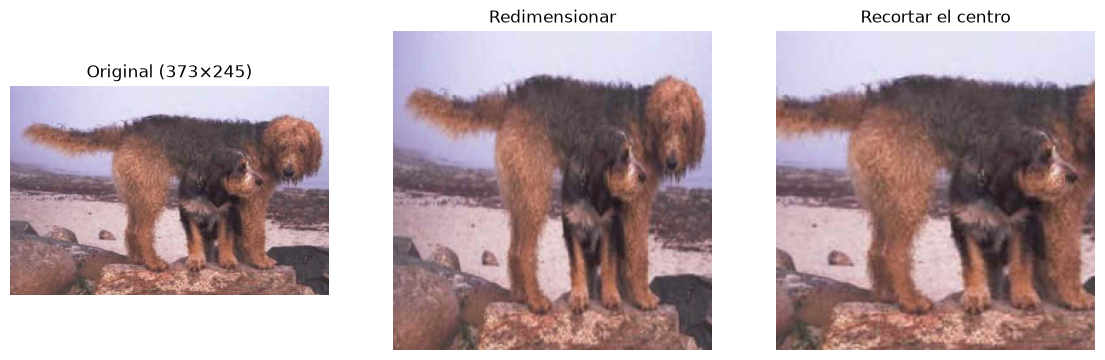

In [13]:
from PIL import ImageOps

IMG_SIZE = 224

original = Image.open(os.path.join(img_dir, "n02091635-otterhound", "n02091635_965.jpg"))

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (titulo, im) in zip(axes, [
        (f"Original ({original.width}×{original.height})", original),
        ("Redimensionar", original.resize((IMG_SIZE, IMG_SIZE))),
        ("Recortar el centro", ImageOps.fit(original, (IMG_SIZE, IMG_SIZE)))]):
    
    ax.imshow(im)
    ax.set_title(titulo)
    ax.axis("off")
plt.show()

En este ejemplo se ven bien los dos problemas. Al redimensionar, los perros quedan más estrechos de lo que son; al recortar el centro, el perro de la derecha pierde parte de la cabeza. Para no decidir a partir de un solo caso, usamos las anotaciones del dataset, que indican con una caja dónde está cada perro, y medimos en todas las imágenes:

* Qué parte del perro (del área de sus cajas) queda dentro del cuadrado central.
* Cuánto se deformaría cada imagen al redimensionarla, según la relación entre su lado mayor y su lado menor.

Parte del perro dentro del recorte: media 89.7%, mediana 92.1%
Imágenes que pierden más del 5% del perro: 55.9%
Imágenes que pierden más del 10% del perro: 45.9%
Imágenes que pierden más del 20% del perro: 20.8%
Proporción lado mayor / lado menor: mediana 1.33
Imágenes con proporción mayor que 1,5 (deformación fuerte al redimensionar): 21.7%


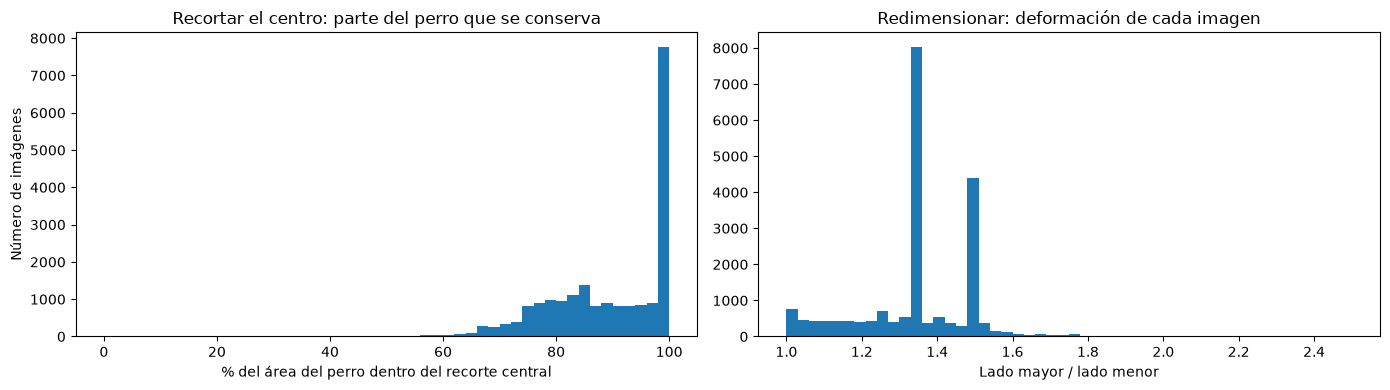

In [14]:
import xml.etree.ElementTree as ET

def fraccion_perro_en_centro(ruta_img, ancho, alto):
    raza, nombre = os.path.basename(os.path.dirname(ruta_img)), os.path.basename(ruta_img)[:-4]
    raiz = ET.parse(os.path.join(ann_dir, raza, nombre)).getroot()
    lado = min(ancho, alto)
    x0, y0 = (ancho - lado) / 2, (alto - lado) / 2
    area_total = area_dentro = 0
    for caja in raiz.iter("bndbox"):
        xmin, ymin, xmax, ymax = (int(caja.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
        area_total += (xmax - xmin) * (ymax - ymin)
        area_dentro += (max(0, min(xmax, x0 + lado) - max(xmin, x0))
                        * max(0, min(ymax, y0 + lado) - max(ymin, y0)))
    return area_dentro / area_total

conservado = np.array([fraccion_perro_en_centro(r, w, h) for r, (w, h) in zip(rutas, tamanos)])
proporcion = np.array([max(w, h) / min(w, h) for w, h in tamanos])

print(f"Parte del perro dentro del recorte: media {conservado.mean():.1%}, mediana {np.median(conservado):.1%}")
for umbral in (0.95, 0.9, 0.8):
    print(f"Imágenes que pierden más del {1 - umbral:.0%} del perro: {(conservado < umbral).mean():.1%}")
print(f"Proporción lado mayor / lado menor: mediana {np.median(proporcion):.2f}")
print(f"Imágenes con proporción mayor que 1,5 (deformación fuerte al redimensionar): {(proporcion > 1.5).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(conservado * 100, bins=50)
axes[0].set_xlabel("% del área del perro dentro del recorte central")
axes[0].set_ylabel("Número de imágenes")
axes[0].set_title("Recortar el centro: parte del perro que se conserva")
axes[1].hist(proporcion, bins=50, range=(1, 2.5))
axes[1].set_xlabel("Lado mayor / lado menor")
axes[1].set_title("Redimensionar: deformación de cada imagen")

plt.tight_layout()
plt.show()

El recorte central conserva de media el 89,7 % del área del perro (mediana 92,1 %), pero en el 20,8 % de las imágenes se pierde más de una quinta parte. Redimensionar no pierde nada, pero la mitad de las imágenes tienen una proporción de 4:3 o más alargada (la mediana es 1,33) y en el 21,7 % la proporción supera 1,5, así que en esas el perro queda claramente deformado.

Con estas medidas ninguna opción es claramente mejor, así que lo decidimos con un experimento. En el apartado 5.3 comparamos la accuracy en validación de una red preentrenada con cada preprocesado, incluida una tercera opción: rellenar con bordes hasta hacer la imagen cuadrada, que ni corta ni deforma a cambio de dedicar parte de los píxeles al relleno. El experimento muestra que recortar el centro es claramente la mejor opción: con la misma red obtiene un 87,2 % de accuracy en validación, frente al 82,8 % de redimensionar y el 78,8 % de rellenar con bordes. Perder a veces una parte del perro le afecta a la red menos que deformarlo o reducir su tamaño en la imagen, así que mantenemos el recorte central.

Para aplicar este preprocesamiento a todo el conjunto de datos creamos una función reutilizable, `cargar_dataset`, que:

1. Descarga el dataset desde Kaggle con `kagglehub`.
2. Procesa cada imagen según dos opciones:
   * **`redimensionar`**: lleva la imagen a 224x224.
   * **`recortar_centro`**: recorta la zona central cuadrada antes de redimensionar a 224x224, para no deformarla.
3. Guarda las imágenes procesadas en una carpeta nueva, en JPEG con calidad 95. Con la calidad por defecto de PIL (75) la recompresión degrada la imagen lo suficiente como para empeorar los modelos, como comprobamos en el apartado 5.3. Si las imágenes ya existen, no se vuelven a procesar.
4. Devuelve una tabla con la ruta de cada imagen, su raza y una etiqueta numérica (de 0 a 119), junto con la lista de clases.

In [15]:
import pandas as pd
from PIL import ImageOps

def cargar_dataset(nombre="jessicali9530/stanford-dogs-dataset",
                   redimensionar=True, recortar_centro=True, img_size=224):
    path = kagglehub.dataset_download(nombre)
    rutas = sorted(glob(os.path.join(path, "images", "Images", "*", "*.jpg")))

    if redimensionar or recortar_centro:
        carpeta_salida = f"stanford_dogs_redim{int(redimensionar)}_recorte{int(recortar_centro)}"
        nuevas_rutas = []
        for ruta in rutas:
            destino = os.path.join(carpeta_salida, os.path.basename(os.path.dirname(ruta)),
                                   os.path.basename(ruta))
            if not os.path.exists(destino):
                os.makedirs(os.path.dirname(destino), exist_ok=True)
                img = Image.open(ruta).convert("RGB")
                if redimensionar and recortar_centro:
                    img = ImageOps.fit(img, (img_size, img_size))       # recorta y redimensiona
                elif redimensionar:
                    img = img.resize((img_size, img_size))              # redimensiona (deforma)
                else:
                    lado = min(img.size)
                    img = ImageOps.fit(img, (lado, lado))               # solo recorta a cuadrado
                img.save(destino, quality=95)
            nuevas_rutas.append(destino)
    else:
        nuevas_rutas = rutas                                            # imágenes originales

    df = pd.DataFrame({"ruta": nuevas_rutas, "raza": [nombre_raza(r) for r in rutas]})
    clases = sorted(df["raza"].unique())
    df["etiqueta"] = df["raza"].map({c: i for i, c in enumerate(clases)})

    print(f"Imágenes: {len(df)} | Clases: {len(clases)} | "
          f"Redimensionar: {redimensionar} | Recortar centro: {recortar_centro}")
    return df, clases

In [16]:
df, clases = cargar_dataset()

Imágenes: 20580 | Clases: 120 | Redimensionar: True | Recortar centro: True


### 3.2. División en entrenamiento, validación y test

Dividimos los datos en 70 % entrenamiento, 15 % validación (para tomar decisiones durante la experimentación) y 15 % test (solo para la evaluación final, con datos no vistos durante el entrenamiento). Para división se aplica estratificación y así mantener la proporción de cada raza en los tres conjuntos, y usa una semilla fija para que las dos estrategias trabajen exactamente con los mismos datos.

In [17]:
from sklearn.model_selection import train_test_split

# Primero separamos el 15 % para test
train_df, test_df = train_test_split(df, test_size=0.15,
                                     stratify=df["etiqueta"], random_state=SEED)

# Del resto, separamos otro 15 % del total para validación
train_df, val_df = train_test_split(train_df, test_size=0.15 / 0.85,
                                    stratify=train_df["etiqueta"], random_state=SEED)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 14406 | Val: 3087 | Test: 3087


### 3.3. Carga de las imágenes

Usamos los conjuntos de entrenamiento, validación y test de la sección anterior 3.2, de forma de que se entrenen y evalúen sobre las mismas imágenes la Estrategia 1 y 2.

Para ello creamos la función `crear_dataset`, que con `tf.data` lee cada imagen, ya recortada y redimensionada a 224x224 por `cargar_dataset`, y la convierte en un tensor. Los píxeles se dejan en el rango 0-255, porque cada estrategia aplica su propia normalización dentro del modelo. Las imágenes decodificadas se guardan en memoria con `cache()` para no leerlas del disco en cada época, se barajan en cada época solo en el conjunto de entrenamiento y se agrupan en lotes de 32.


In [18]:
import time
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASES = len(clases)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def crear_dataset(df, barajar=False):
    ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["etiqueta"].values))
    # Lee cada imagen (ya recortada a 224x224 por cargar_dataset) y la convierte en tensor
    ds = ds.map(lambda ruta, etiqueta: (
                    tf.ensure_shape(tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3),
                                    (IMG_SIZE, IMG_SIZE, 3)),
                    etiqueta),
                num_parallel_calls=AUTOTUNE).cache()
    if barajar:
        ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y))
    return ds.prefetch(AUTOTUNE)


train_ds = crear_dataset(train_df, barajar=True)
val_ds = crear_dataset(val_df)
test_ds = crear_dataset(test_df)

imagenes, _ = next(iter(val_ds))
print("Lote:", imagenes.shape, "| Rango de píxeles:",
      float(tf.reduce_min(imagenes)), "-", float(tf.reduce_max(imagenes)))

Lote: (32, 224, 224, 3) | Rango de píxeles: 0.0 - 255.0


Definimos también una función para dibujar las curvas de entrenamiento, que usaremos en todos los experimentos de las dos estrategias. Opcionalmente marca con una línea horizontal un valor de referencia en validación.

In [19]:
def graficar_curvas(historiales, titulo, referencia=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for nombre, h in historiales.items():
        epocas = range(1, len(h["loss"]) + 1)
        for ax, metrica in zip(axes, ["loss", "accuracy"]):
            linea, = ax.plot(epocas, h[f"val_{metrica}"], marker=".", label=f"{nombre} (val)")
            ax.plot(epocas, h[metrica], linestyle="--", color=linea.get_color(),
                    alpha=0.6, label=f"{nombre} (train)")
    if referencia is not None:
        nombre_ref, valores = referencia
        for ax, metrica in zip(axes, ["loss", "accuracy"]):
            ax.axhline(valores[metrica], color="gray", linestyle=":", label=nombre_ref)
    axes[0].set_title("Pérdida")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## 4. Estrategia 1: entrenamiento desde cero (*from scratch*)

En esta estrategia diseñamos y entrenamos una red convolucional desde cero. Partimos de un modelo base y, a partir de sus resultados, introducimos mejoras para reducir el sobreajuste.

### 4.1. Carga de los datos

Usamos los conjuntos `train_ds`, `val_ds` y `test_ds` creados en la sección 3.3, de forma que esta estrategia se evalúa sobre las mismas imágenes que la Estrategia 2. La normalización de los píxeles al rango [0, 1] se aplica dentro del modelo, con una capa `Rescaling(1./255)`.

## 4.2. Diseño de la arquitectura

Una vez tenemos los datos, tenemos que diseñar la *CNN*, para ello contamos con una capa de entrada para imágenes de *224x224x3*. Esta cuenta con la siguiente estructura:

La red recibe imágenes de 224x224x3 y tiene la siguiente estructura:

```text
Imagen 224×224×3
       ↓
Rescaling (1/255)
       ↓
Conv2D (32 filtros, 5×5) + BatchNorm    → 224×224×32
Conv2D (32 filtros, 3×3) + BatchNorm    → 224×224×32
MaxPooling                              → 112×112×32
       ↓
Conv2D (64 filtros, 3×3) + BatchNorm    → 112×112×64
Conv2D (64 filtros, 3×3) + BatchNorm    → 112×112×64
MaxPooling                              → 56×56×64
       ↓
Conv2D (128 filtros, 3×3) + BatchNorm   → 56×56×128
Conv2D (128 filtros, 3×3) + BatchNorm   → 56×56×128
MaxPooling                              → 28×28×128
       ↓
Conv2D (256 filtros, 3×3) + BatchNorm   → 28×28×256
MaxPooling                              → 14×14×256
       ↓
Conv2D (256 filtros, 3×3) + BatchNorm   → 14×14×256
MaxPooling                              → 7×7×256
       ↓
Flatten                                 → 12544
Dense (256 neuronas, ReLU)
Dropout (0.5)
Dense (120 neuronas + Softmax)
```

En primer lugar, la capa `Rescaling(1./255)` lleva los píxeles al rango [0, 1], lo que hace los gradientes más estables y acelera la convergencia.

A continuación, la red se organiza en bloques convolucionales en los que el número de filtros aumenta progresivamente, de 32 a 256. Cada convolución usa *padding* (`same`) para conservar el tamaño y va seguida de una capa de `BatchNormalization`, que aumenta la velocidad del entrenamiento mediante la normalización de las activaciones de la capa anterior, restando la media y dividiendo por la desviación estándar del mini-lote actual. Cabe destacar la primera convolución, que utiliza un kernel de 5x5 en lugar de 3x3 para abarcar una región más amplia de la imagen al inicio.

Al final de cada bloque, una capa `MaxPooling` reduce a la mitad el tamaño (224 → 112 → 56 → 28 → 14 → 7), conservando las activaciones más relevantes. Esto reduce el coste computacional, ya que se cuentan con menos datos a procesar durante el entrenamiento, de modo que las capas más profundas analizan regiones cada vez mayores de la imagen. Así, mientras las primeras capas detectan patrones simples (bordes, colores, texturas), las más profundas combinan esos patrones en características más complejas, por ello se cuentan con más filtros al final.

En la primera convolución se utiliza un kernel de 5×5 en lugar de 3×3. Con ello, para captar más características al inicio. En el resto de capas se emplean kernels de 3×3, que ofrecen un buen equilibrio entre capacidad y número de parámetros.

Al final se interconecta con una capa densa de 256 neuronas, que para poder obtener los datos de la red convolucional, se utiliza `Flatten` que permite convertir los datos a un único tensor que puede utilizar la red final para predecir a que clase pertenece la imagen. También se cuenta con una capa `Dropout` al final para intentar prevenir sobreajuste.

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


def build_model(name, augmentation=None):
    scratch = Sequential(name=name)
    scratch.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))

    if augmentation is not None:
        scratch.add(augmentation)

    scratch.add(layers.Rescaling(1./255))

    # 224x224
    scratch.add(layers.Conv2D(32, (5, 5), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.Conv2D(32, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.MaxPooling2D((2, 2)))

    # 112x112
    scratch.add(layers.Conv2D(64, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.Conv2D(64, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.MaxPooling2D((2, 2)))

    # 56x56
    scratch.add(layers.Conv2D(128, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.Conv2D(128, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.MaxPooling2D((2, 2)))

    # 28x28
    scratch.add(layers.Conv2D(256, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.MaxPooling2D((2, 2)))   # 14x14
    scratch.add(layers.Conv2D(256, (3, 3), activation="relu", padding="same"))
    scratch.add(layers.BatchNormalization())
    scratch.add(layers.MaxPooling2D((2, 2)))   # 7x7

    # Clasificador
    scratch.add(layers.Flatten())
    scratch.add(layers.Dense(256, activation="relu"))
    scratch.add(layers.Dropout(0.5))
    scratch.add(layers.Dense(NUM_CLASES, activation="softmax"))

    return scratch

In [ ]:
# Carpeta donde guardar los modelos entrenados:
# en Colab, en Google Drive (para no perderlos si se corta la sesión); en local, en una carpeta "modelos"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA_MODELOS = "/content/drive/MyDrive/07MIAR_modelos"
except ImportError:
    CARPETA_MODELOS = "modelos"
os.makedirs(CARPETA_MODELOS, exist_ok=True)

### 4.3. Entrenamiento del modelo base
Para el primer entrenamiento utilizaremos el optimizador `Adam`, ya que es el más habitual. Puesto que las etiquetas están codificadas con valores enteros (de 0 a 119, una por cada raza), se utiliza `sparse_categorical_crossentropy` como función de pérdida. Además de la accuracy, Además de la accuracy, medimos la *top-5 accuracy*, que indica si la raza real se encuentra entre las cinco razas más probables según el modelo. Así podemos identificar si la red confunde unas razas con otras por sus parecidos (por ejemplo, un pastor alemán y un pastor belga).

También para el entrenamiento, contamos con una serie de "callbacks" por una parte, para evitar el sobreajuste, *overfitting*, se cuenta con `EarlyStopping` que observa el valor de *val_loss* durante el entrenamiento y cuando observa que no mejora durante varias épocas, se queda con el mejor valor previo, evitando asi llegar a un punto de sobreajuste.

Por otra parte se cuenta con `ReduceLROnPlateau`, un mecanismo de programación de la tasa de aprendizaje que reduce dinámicamente el valor de dicha tasa, si en el mismo caso anterior, el valor de *val_loss* deja de mejorar.

Se entrena la red con un tamaño de lote de 32 elementos, evaluados durante 60 épocas, donde rara vez se llegará a dicho valor, ya que como se comentaba, se cuentan con dichos *callbacks* que una vez que la métrica *val_loss* deje de mejorar, paramos el entrenamiento.

In [22]:
def crear_callbacks():
    return [
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
    ]

metricas_scratch = ["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")]

scratch_model = build_model("scratch_model")
scratch_model.compile(optimizer=Adam(learning_rate=1e-3),
                      loss="sparse_categorical_crossentropy",
                      metrics=metricas_scratch)
scratch_model.summary()

Model: "scratch_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 14, 14, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 14, 14, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 4,419,992 (16.86 MB)

 Trainable params: 4,418,072 (16.85 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
history_scratch = scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    callbacks=crear_callbacks()
)

In [ ]:
scratch_model.save(os.path.join(CARPETA_MODELOS, "scratch_model.keras"))
pd.DataFrame(history_scratch.history).to_csv(
    os.path.join(CARPETA_MODELOS, "historia_scratch.csv"), index=False)

In [ ]:
graficar_curvas({"Modelo base": history_scratch.history}, "Estrategia 1: modelo base")

COMPLETAR: comentar las curvas del modelo base (accuracy final en validación, si hay sobreajuste, en qué época se para).

### 4.4. Mejora con *data augmentation* y *weight decay*

Como mejora a la red, se propone añadir una capa de *augmentation* que produce variaciones del conjunto de entrenamiento, en este caso mediante varias funciones que alteran ligeramente la imagen dada, como traslaciones, modificación del contraste y zoom entre otras funciones. Estas capas solo actúan durante el entrenamiento, en validación y test las imágenes no se modifican. Para su creación se utiliza la misma función `build_model` pero añadiendo dicha capa.

Posteriormente se modifica el algoritmo de optimización con `AdamW`, una variante de Adam que incorpora *weight decay*: en cada paso del entrenamiento reduce ligeramente el valor de los pesos, lo que penaliza los pesos grandes y ayuda a reducir el sobreajuste.

Y se vuelve a entrenar la red, a continuación observamos los resultados.

In [23]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="data_augmentation")

metricas_aug = ["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")]

scratch_model_aug = build_model("scratch_model_aug", augmentation=data_augmentation)
scratch_model_aug.compile(optimizer=AdamW(learning_rate=1e-3, weight_decay=1e-4),
                          loss="sparse_categorical_crossentropy",
                          metrics=metricas_aug)
scratch_model_aug.summary()

Model: "scratch_model_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 224, 224, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 14, 14, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,419,992 (16.86 MB)

 Trainable params: 4,418,072 (16.85 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
history_aug = scratch_model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    callbacks=crear_callbacks()
)

In [ ]:
scratch_model_aug.save(os.path.join(CARPETA_MODELOS, "scratch_model_aug.keras"))
pd.DataFrame(history_aug.history).to_csv(
    os.path.join(CARPETA_MODELOS, "historia_aug.csv"), index=False)

In [ ]:
graficar_curvas({"Modelo base": history_scratch.history,
                 "Augmentation + AdamW": history_aug.history},
                "Estrategia 1: modelo base frente a modelo con augmentation y AdamW")

COMPLETAR: comparar los dos modelos

### 4.5. Evaluación en test

Elegimos el modelo final con el conjunto de validación, quedándonos con el de menor pérdida. Después evaluamos los dos modelos sobre el conjunto de test, no usado para entrenar.

In [ ]:
modelos_scratch = {
    "Modelo base": scratch_model,
    "Augmentation + AdamW": scratch_model_aug,
}

filas = []
for nombre, modelo in modelos_scratch.items():
    val_loss, val_acc, val_top5 = modelo.evaluate(val_ds, verbose=0)
    _, test_acc, test_top5 = modelo.evaluate(test_ds, verbose=0)
    filas.append({"Modelo": nombre, "Pérdida val": val_loss, "Accuracy val": val_acc,
                  "Top-5 val": val_top5, "Accuracy test": test_acc, "Top-5 test": test_top5})

resultados_test_scratch = pd.DataFrame(filas).set_index("Modelo").round(4)
modelo_final_scratch = resultados_test_scratch["Pérdida val"].idxmin()
print("Modelo final (menor pérdida en validación):", modelo_final_scratch)
resultados_test_scratch

COMPLETAR parecido a Estrategia 2

### 4.6. Conclusiones de la Estrategia 1

## 5. Estrategia 2: redes preentrenadas (*transfer learning* y *fine-tuning*)

En esta estrategia partimos de redes ya entrenadas en ImageNet y las adaptamos a nuestras 120 razas. Lo hacemos en dos fases:

1. **Extracción de características**: congelamos la base convolucional y entrenamos solo un clasificador nuevo encima. Es rápido, así que lo usamos para comparar varias arquitecturas y ajustar el clasificador.
2. **Fine-tuning**: con la mejor configuración, descongelamos las últimas capas de la base y las reentrenamos con una tasa de aprendizaje baja.

Hay que tener en cuenta lo que vimos en las anotaciones: Stanford Dogs se construyó a partir de ImageNet. Las redes preentrenadas ya conocen estas razas y probablemente han visto parte de estas mismas fotos durante su entrenamiento, incluidas algunas de nuestro conjunto de test. Sus resultados serán, por tanto, más optimistas que los que obtendríamos con un dataset nuevo. Lo tendremos presente al analizar los resultados y en la comparación final.

### 5.1. Carga de los datos

Usamos los conjuntos `train_ds`, `val_ds` y `test_ds` creados en la sección 3.3, de forma que esta estrategia se evalúa sobre las mismas imágenes que la Estrategia 1.

Los datos de la sección 3.3 se mantienen en el rango 0-255 y cada modelo aplica su propia función `preprocess_input`.

### 5.2. Extracción de características: comparación de arquitecturas

Comparamos tres redes preentrenadas en ImageNet de diseño y tamaño muy distintos:

* **ResNet50**: red residual clásica, con unos 23,6 millones de parámetros en la base.
* **EfficientNetB0**: escala de forma equilibrada la profundidad, la anchura y la resolución; unos 4 millones.
* **MobileNetV2**: pensada para dispositivos con pocos recursos; unos 2,3 millones.

Mientras la base está congelada, su salida para una imagen no cambia de una época a otra. Por eso pasamos cada imagen por la base una sola vez, guardamos su vector de características (la salida tras el `GlobalAveragePooling`) y entrenamos el clasificador directamente sobre esos vectores. El resultado es el mismo que entrenar el modelo completo con la base congelada y sin data augmentation, pero en una fracción del tiempo, y así comparamos las tres redes en igualdad de condiciones.

El clasificador es el mismo para las tres: un `Dropout(0.3)` y una capa `Dense` de 120 neuronas con softmax. Se entrena con Adam (tasa de aprendizaje 1e-3) y *early stopping* sobre la pérdida de validación. Además de la accuracy medimos la *top-5 accuracy* (la raza correcta está entre las 5 más probables), útil en un problema con tantas razas parecidas.

Cuando haya que elegir entre configuraciones usaremos la pérdida de validación, que es la misma métrica que vigila el early stopping y varía de forma más continua que la accuracy. Hay que tener en cuenta que, con 3.087 imágenes de validación y una accuracy en torno al 87 %, el error típico de la accuracy es de unos 0,6 puntos, así que diferencias menores no son significativas.

In [24]:
BASES = {
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    "MobileNetV2": (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
}


def crear_base(nombre):
    constructor, preprocesado = BASES[nombre]
    base = constructor(include_top=False, weights="imagenet",
                       input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base.trainable = False
    return base, preprocesado


def extraer_caracteristicas(base, preprocesado, conjuntos):
    paso = tf.function(lambda x: base(preprocesado(x), training=False))
    resultado = {}
    for nombre, ds in conjuntos.items():
        X, y = [], []
        for imagenes, etiquetas in ds:
            X.append(paso(imagenes).numpy())
            y.append(etiquetas.numpy())
        resultado[nombre] = (np.concatenate(X), np.concatenate(y))
    return resultado


def metricas():
    return ["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")]


def entrenar_clasificador(datos, dropout):
    (X_tr, y_tr), (X_va, y_va) = datos["train"], datos["val"]
    keras.utils.set_random_seed(SEED)
    clasificador = keras.Sequential([
        layers.Input(shape=(X_tr.shape[1],)),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ], name="clasificador")
    clasificador.compile(optimizer=keras.optimizers.Adam(1e-3),
                         loss="sparse_categorical_crossentropy", metrics=metricas())
    historia = clasificador.fit(
        X_tr, y_tr, validation_data=(X_va, y_va), epochs=100, batch_size=64, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                 restore_best_weights=True)])
    return clasificador, historia.history


def resumen(clasificador, historia, datos):
    (X_tr, y_tr), (X_va, y_va) = datos["train"], datos["val"]
    _, train_acc, _ = clasificador.evaluate(X_tr, y_tr, verbose=0)
    val_loss, val_acc, val_top5 = clasificador.evaluate(X_va, y_va, verbose=0)
    return {"Épocas": len(historia["loss"]), "Accuracy train": train_acc,
            "Accuracy val": val_acc, "Top-5 val": val_top5, "Pérdida val": val_loss}

En la tabla, la accuracy de entrenamiento se calcula con los pesos finales y sin dropout, para que sea comparable con la de validación.

In [ ]:
caracteristicas, historiales_fe, filas = {}, {}, []

for nombre in BASES:
    base, preprocesado = crear_base(nombre)
    inicio = time.time()
    caracteristicas[nombre] = extraer_caracteristicas(
        base, preprocesado, {"train": train_ds, "val": val_ds, "test": test_ds})
    tiempo = time.time() - inicio

    clasificador, historiales_fe[nombre] = entrenar_clasificador(caracteristicas[nombre], dropout=0.3)
    filas.append({"Modelo": nombre,
                  "Parámetros base (M)": base.count_params() / 1e6,
                  "Tiempo extracción (s)": tiempo,
                  **resumen(clasificador, historiales_fe[nombre], caracteristicas[nombre])})
    del base

resultados_fe = pd.DataFrame(filas).set_index("Modelo").round(4)
resultados_fe

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Parámetros base (M),Tiempo extracción (s),Épocas,Accuracy train,Accuracy val,Top-5 val,Pérdida val
Modelo,,,,,,,
ResNet50,23.5877,135.0655,9,0.9638,0.8322,0.9819,0.5265
EfficientNetB0,4.0496,60.8522,14,0.9721,0.8759,0.9887,0.3992
MobileNetV2,2.2580,39.7465,13,0.9833,0.8707,0.9896,0.3983


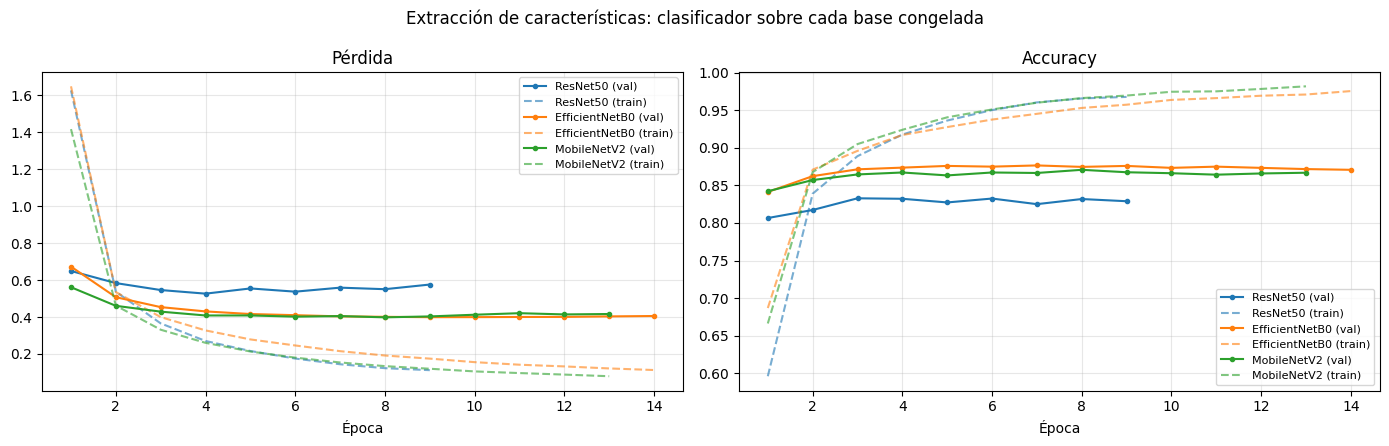

In [ ]:
graficar_curvas(historiales_fe, "Extracción de características: clasificador sobre cada base congelada")

Las tres redes superan con mucho la referencia de un clasificador aleatorio (0,8 %). Incluso la peor, ResNet50, acierta la raza del 83,2 % de las imágenes de validación, y en más del 98 % de los casos la raza correcta está entre sus 5 primeras opciones. Las características aprendidas en ImageNet sirven casi directamente para nuestro problema, algo esperable porque las 120 razas de Stanford Dogs son también clases de ImageNet (los nombres de las carpetas, como `n02085620`, son sus identificadores en ImageNet).

EfficientNetB0 y MobileNetV2 quedan prácticamente empatadas: 87,6 % y 87,1 % de accuracy, con una pérdida de 0,399 y 0,398. La diferencia está muy por debajo del error típico de 0,6 puntos. ResNet50 queda unos 4 puntos por detrás pese a tener seis veces más parámetros que EfficientNetB0, así que en este caso la arquitectura importa más que el tamaño. Siguiendo el criterio de la pérdida de validación elegimos MobileNetV2, que además es la más ligera y la más rápida: tarda 40 segundos en extraer las características de todo el dataset, frente a 61 de EfficientNetB0 y 135 de ResNet50.

En las curvas, la accuracy de validación de las tres redes se estanca a partir de la tercera o cuarta época, mientras que la de entrenamiento sigue subiendo hasta el 96-98 %. El clasificador sobreajusta: memoriza el conjunto de entrenamiento sin mejorar en validación, y el early stopping lo detiene cuando la pérdida de validación deja de bajar. En ResNet50 esa pérdida incluso empieza a subir. Intentamos reducir este sobreajuste en el apartado 5.4.

### 5.3. Comprobación del preprocesado

En la sección 3 vimos que recortar el centro y redimensionar tienen inconvenientes parecidos, y lo dejamos pendiente de comprobar. Ahora que tenemos una forma rápida de entrenar (base congelada y características precalculadas), usamos la mejor red del apartado anterior para comparar varios preprocesados en las mismas condiciones. Todos parten de las imágenes originales:

* **Recortar el centro** y redimensionar a 224x224.
* **Redimensionar** la imagen completa a 224x224, deformándola.
* **Rellenar con bordes**: redimensionar manteniendo la proporción y completar con negro hasta 224x224.
* **Recortar el centro y comprimir en JPEG con calidad 75 o 95**, para medir cuánto afecta guardar las imágenes procesadas en disco, que es lo que hace `cargar_dataset`.

Como referencia añadimos el resultado del apartado 5.2, obtenido con los archivos que genera `cargar_dataset`.

In [ ]:
mejor_base = resultados_fe["Pérdida val"].idxmin()
print("Base elegida:", mejor_base)


def ruta_original(ruta):
    return os.path.join(img_dir, os.path.basename(os.path.dirname(ruta)), os.path.basename(ruta))


def recortar_centro(img):
    alto, ancho = tf.shape(img)[0], tf.shape(img)[1]
    lado = tf.minimum(alto, ancho)
    return tf.image.crop_to_bounding_box(img, (alto - lado) // 2, (ancho - lado) // 2, lado, lado)


def redimensionar(img):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bicubic", antialias=True)
    return tf.clip_by_value(img, 0, 255)


def rellenar(img):
    img = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE, method="bicubic", antialias=True)
    return tf.clip_by_value(img, 0, 255)


def comprimir_jpeg(img, calidad):
    img = tf.cast(tf.round(img), tf.uint8)
    return tf.cast(tf.io.decode_jpeg(tf.io.encode_jpeg(img, quality=calidad), channels=3), tf.float32)


PREPROCESADOS = {
    "Recortar el centro": lambda img: redimensionar(recortar_centro(img)),
    "Redimensionar (deforma)": redimensionar,
    "Rellenar con bordes": rellenar,
    "Recortar el centro + JPEG calidad 75": lambda img: comprimir_jpeg(redimensionar(recortar_centro(img)), 75),
    "Recortar el centro + JPEG calidad 95": lambda img: comprimir_jpeg(redimensionar(recortar_centro(img)), 95),
}


def dataset_original(df, transformar):
    def leer(ruta, etiqueta):
        img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
        img = transformar(tf.cast(img, tf.float32))
        img.set_shape((IMG_SIZE, IMG_SIZE, 3))
        return img, etiqueta
    rutas = df["ruta"].map(ruta_original).values
    ds = tf.data.Dataset.from_tensor_slices((rutas, df["etiqueta"].values))
    return ds.map(leer, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)


base, preprocesado = crear_base(mejor_base)
columnas = ["Épocas", "Accuracy train", "Accuracy val", "Top-5 val", "Pérdida val"]
filas = [{"Preprocesado": "Archivos de cargar_dataset (apartado 5.2)",
          **resultados_fe.loc[mejor_base, columnas].to_dict()}]
for nombre, transformar in PREPROCESADOS.items():
    datos = extraer_caracteristicas(base, preprocesado, {
        "train": dataset_original(train_df, transformar),
        "val": dataset_original(val_df, transformar)})
    clasificador, historia = entrenar_clasificador(datos, dropout=0.3)
    filas.append({"Preprocesado": nombre, **resumen(clasificador, historia, datos)})
del base

resultados_preprocesado = pd.DataFrame(filas).set_index("Preprocesado").round(4)
resultados_preprocesado

Base elegida: MobileNetV2


,Épocas,Accuracy train,Accuracy val,Top-5 val,Pérdida val
Preprocesado,,,,,
Archivos de cargar_dataset (apartado 5.2),13.0,0.9833,0.8707,0.9896,0.3983
Recortar el centro,10.0,0.9734,0.8720,0.9909,0.3826
Redimensionar (deforma),10.0,0.9604,0.8280,0.9819,0.5203
Rellenar con bordes,9.0,0.9279,0.7875,0.9695,0.6580
Recortar el centro + JPEG calidad 75,10.0,0.9639,0.8523,0.9854,0.4675
Recortar el centro + JPEG calidad 95,10.0,0.9710,0.8720,0.9900,0.3886


El resultado es claro:

* **Recortar el centro es la mejor opción** (87,2 % de accuracy y 0,383 de pérdida). Redimensionar baja al 82,8 % y rellenar con bordes al 78,8 %. A la red le afecta más que el perro esté deformado que perder a veces una parte de él, y rellenar es la peor opción porque el perro ocupa menos píxeles y parte de la imagen no tiene información.
* **La compresión al guardar sí importa.** Con la calidad por defecto de PIL (75) la accuracy cae 2 puntos, hasta el 85,2 %, y la pérdida sube de 0,383 a 0,468. Con calidad 95 el resultado es el mismo que sin comprimir. Por eso `cargar_dataset` guarda las imágenes con calidad 95. En una versión anterior de este notebook se guardaban con calidad 75 y las tres redes del apartado 5.2 daban entre 1 y 2 puntos menos, que es lo que nos llevó a hacer esta comprobación.
* Los archivos que genera `cargar_dataset` dan prácticamente lo mismo que el recorte hecho en memoria (87,1 % frente a 87,2 %), así que el preprocesado de la sección 3 es el adecuado y lo mantenemos para el resto de experimentos.

### 5.4. Ajuste del clasificador

Con la base elegida, probamos distintos valores de dropout en el clasificador, ya que con las características precalculadas cada prueba tarda solo unos segundos. El dropout es la única regularización del clasificador, así que es el parámetro que más directamente actúa sobre la diferencia entre entrenamiento y validación.

In [ ]:
clasificadores, historiales_dropout, filas = {}, {}, []
for dropout in [0.0, 0.3, 0.5, 0.7]:
    clasificador, historia = entrenar_clasificador(caracteristicas[mejor_base], dropout)
    clasificadores[dropout] = clasificador
    historiales_dropout[f"Dropout {dropout}"] = historia
    filas.append({"Dropout": dropout, **resumen(clasificador, historia, caracteristicas[mejor_base])})

resultados_dropout = pd.DataFrame(filas).set_index("Dropout").round(4)
resultados_dropout

,Épocas,Accuracy train,Accuracy val,Top-5 val,Pérdida val
Dropout,,,,,
0.0,12,0.9876,0.8682,0.9900,0.4063
0.3,13,0.9833,0.8707,0.9896,0.3983
0.5,11,0.9633,0.8643,0.9919,0.3989
0.7,14,0.9575,0.8724,0.9916,0.3912


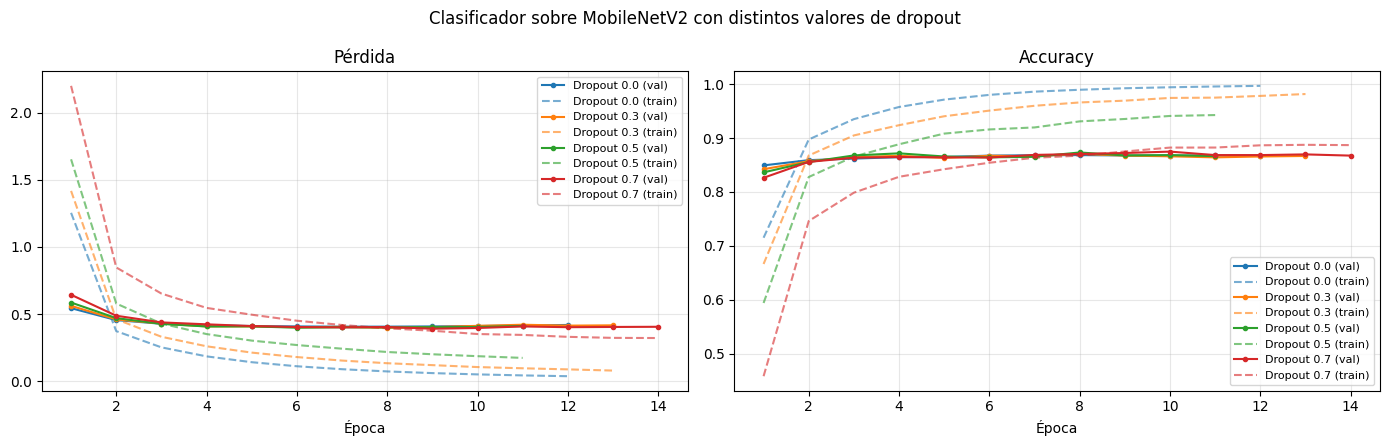

In [ ]:
graficar_curvas(historiales_dropout, f"Clasificador sobre {mejor_base} con distintos valores de dropout")

Las diferencias de accuracy entre los cuatro valores son pequeñas (del 86,4 % al 87,2 %), del orden del error típico, así que el dropout apenas cambia el resultado en validación. Lo que sí cambia es el sobreajuste: al pasar de 0 a 0,7 la accuracy de entrenamiento baja del 98,8 % al 95,8 % sin perder nada en validación, es decir, el clasificador memoriza menos el conjunto de entrenamiento. Con 0,7 se obtiene además la menor pérdida de validación (0,391), así que es el valor que usamos para el fine-tuning.

### 5.5. Fine-tuning

Con la base congelada la red solo puede recombinar características aprendidas para ImageNet. En el fine-tuning dejamos que las últimas capas de la base también se ajusten a nuestro problema. Seguimos el procedimiento habitual:

1. **Partimos del clasificador ya entrenado** en el apartado anterior. Con un clasificador inicializado al azar, los gradientes de las primeras épocas serían grandes y estropearían los pesos preentrenados.
2. **Descongelamos solo las últimas capas de la base.** Las primeras detectan patrones genéricos (bordes, texturas) que sirven tal cual, mientras que las últimas codifican características más ligadas a las clases de ImageNet.
3. **Usamos una tasa de aprendizaje baja**, para ajustar los pesos sin alejarlos demasiado de los originales.
4. **Mantenemos las capas de `BatchNormalization` congeladas y en modo inferencia** (`training=False`). Sus estadísticas se calcularon sobre ImageNet y recalcularlas con lotes de 32 imágenes desestabiliza el entrenamiento.

Como ahora sí entrenamos sobre las imágenes, añadimos data augmentation (volteo horizontal, rotación y zoom ligeros) para frenar el sobreajuste, que será mayor al haber más parámetros entrenables. Usamos transformaciones suaves porque las proporciones y la postura del perro son información útil para distinguir razas.

Probamos tres variantes: descongelar solo el último bloque de la base o los dos últimos, con una tasa de aprendizaje de 1e-5, y descongelar el último bloque con una tasa diez veces mayor (1e-4), por si 1e-5 fuera demasiado conservadora para mover los pesos en pocas épocas. Antes de entrenar evaluamos cada modelo en validación para tener el punto de partida, que debe coincidir con el clasificador del apartado 5.4.

In [ ]:
PRIMERA_CAPA_ENTRENABLE = {
    "ResNet50": {"último": "conv5_block3_1_conv", "dos últimos": "conv5_block2_1_conv"},
    "EfficientNetB0": {"último": "block7a_expand_conv", "dos últimos": "block6a_expand_conv"},
    "MobileNetV2": {"último": "block_16_expand", "dos últimos": "block_15_expand"},
}

VARIANTES_FT = {
    "Último bloque, lr 1e-5": ("último", 1e-5),
    "Dos últimos bloques, lr 1e-5": ("dos últimos", 1e-5),
    "Último bloque, lr 1e-4": ("último", 1e-4),
}

aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")


def crear_modelo_ft(primera_capa_entrenable, clasificador, tasa):
    base, preprocesado = crear_base(mejor_base)
    cabeza = keras.models.clone_model(clasificador)
    cabeza.set_weights(clasificador.get_weights())

    entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = aumento(entrada)
    x = layers.Lambda(preprocesado, name="preprocesado")(x)
    x = base(x, training=False)
    modelo = keras.Model(entrada, cabeza(x), name=f"{mejor_base}_finetuning")

    base.trainable = True
    indice = [capa.name for capa in base.layers].index(primera_capa_entrenable)
    for i, capa in enumerate(base.layers):
        capa.trainable = i >= indice and not isinstance(capa, layers.BatchNormalization)
    modelo.compile(optimizer=keras.optimizers.Adam(tasa),
                   loss="sparse_categorical_crossentropy", metrics=metricas())
    return modelo, base


mejor_dropout = resultados_dropout["Pérdida val"].idxmin()
clasificador_base = clasificadores[mejor_dropout]
print("Dropout del clasificador:", mejor_dropout)

modelos_ft, historiales_ft, filas = {}, {}, []
for variante, (bloques, tasa) in VARIANTES_FT.items():
    keras.utils.set_random_seed(SEED)
    modelo, base = crear_modelo_ft(PRIMERA_CAPA_ENTRENABLE[mejor_base][bloques], clasificador_base, tasa)
    inicial = dict(zip(["loss", "accuracy", "top5"], modelo.evaluate(val_ds, verbose=0)))

    inicio = time.time()
    historia = modelo.fit(
        train_ds, validation_data=val_ds, epochs=20, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                 restore_best_weights=True)])
    final = dict(zip(["loss", "accuracy", "top5"], modelo.evaluate(val_ds, verbose=0)))

    modelos_ft[variante], historiales_ft[variante] = modelo, historia.history
    filas.append({
        "Variante": variante,
        "Capas entrenables": sum(c.trainable for c in base.layers),
        "Parámetros entrenables (M)": sum(np.prod(w.shape) for w in modelo.trainable_weights) / 1e6,
        "Épocas": len(historia.history["loss"]),
        "Minutos": (time.time() - inicio) / 60,
        "Accuracy val inicial": inicial["accuracy"],
        "Accuracy val final": final["accuracy"],
        "Pérdida val inicial": inicial["loss"],
        "Pérdida val final": final["loss"],
    })
    print(f"{variante}: accuracy val {inicial['accuracy']:.4f} -> {final['accuracy']:.4f}\n")

resultados_ft = pd.DataFrame(filas).set_index("Variante").round(4)
resultados_ft

Dropout del clasificador: 0.7
Epoch 1/20
451/451 - 40s - 88ms/step - accuracy: 0.8115 - loss: 0.5875 - top5: 0.9817 - val_accuracy: 0.8788 - val_loss: 0.3972 - val_top5: 0.9896
Epoch 2/20
451/451 - 39s - 86ms/step - accuracy: 0.8166 - loss: 0.5772 - top5: 0.9823 - val_accuracy: 0.8743 - val_loss: 0.3953 - val_top5: 0.9896
Epoch 3/20
451/451 - 34s - 75ms/step - accuracy: 0.8288 - loss: 0.5414 - top5: 0.9824 - val_accuracy: 0.8766 - val_loss: 0.3891 - val_top5: 0.9906
Epoch 4/20
451/451 - 33s - 73ms/step - accuracy: 0.8268 - loss: 0.5359 - top5: 0.9839 - val_accuracy: 0.8769 - val_loss: 0.3909 - val_top5: 0.9896
Epoch 5/20
451/451 - 33s - 74ms/step - accuracy: 0.8282 - loss: 0.5305 - top5: 0.9849 - val_accuracy: 0.8753 - val_loss: 0.3940 - val_top5: 0.9903
Epoch 6/20
451/451 - 41s - 90ms/step - accuracy: 0.8303 - loss: 0.5218 - top5: 0.9860 - val_accuracy: 0.8772 - val_loss: 0.3862 - val_top5: 0.9909
Epoch 7/20
451/451 - 33s - 74ms/step - accuracy: 0.8384 - loss: 0.4954 - top5: 0.9858 - 

,Capas entrenables,Parámetros entrenables (M),Épocas,Minutos,Accuracy val inicial,Accuracy val final,Pérdida val inicial,Pérdida val final
Variante,,,,,,,,
"Último bloque, lr 1e-5",8,1.0328,9,5.5415,0.8724,0.8772,0.3912,0.3862
"Dos últimos bloques, lr 1e-5",14,1.3486,8,4.8097,0.8724,0.8792,0.3912,0.3880
"Último bloque, lr 1e-4",8,1.0328,7,4.0289,0.8724,0.8662,0.3912,0.4282


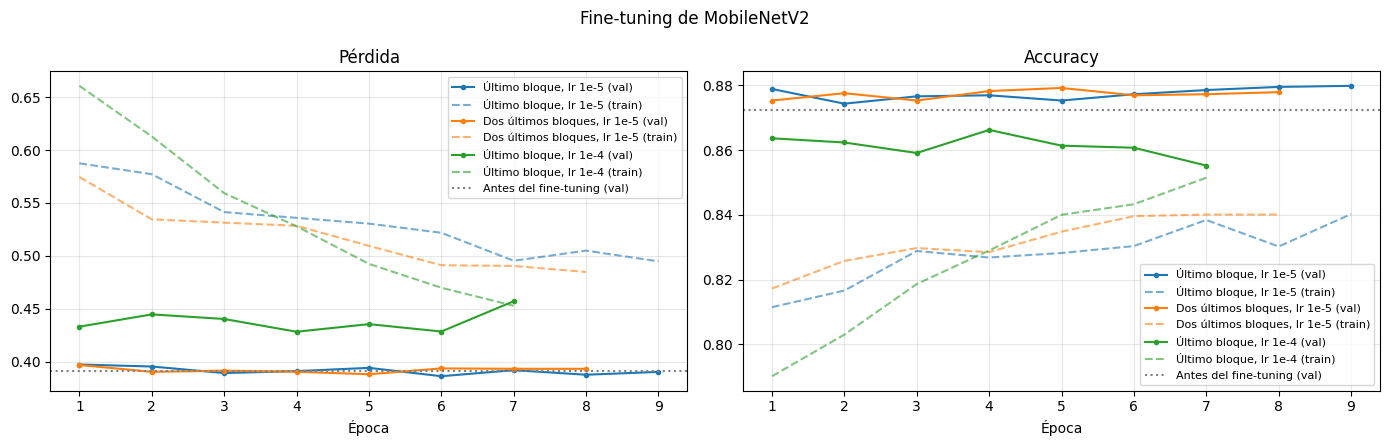

In [ ]:
graficar_curvas(historiales_ft, f"Fine-tuning de {mejor_base}",
                referencia=("Antes del fine-tuning (val)", inicial))

Con una tasa de aprendizaje de 1e-5 el fine-tuning mejora un poco el punto de partida. Descongelando el último bloque, la pérdida de validación baja de 0,391 a 0,386 y la accuracy sube del 87,2 % al 87,7 %; descongelando los dos últimos, la accuracy llega al 87,9 %. Son mejoras del orden del error típico, así que no podemos afirmar que sean reales. Con una tasa de 1e-4 el modelo empeora desde la primera época (86,6 % de accuracy y una pérdida de 0,428): la tasa es demasiado alta y los pesos preentrenados se alejan de un punto que ya era muy bueno. En sus curvas se ve además cómo la pérdida de entrenamiento baja rápido mientras la de validación sube, una señal clara de sobreajuste.

En las curvas, la accuracy de entrenamiento queda por debajo de la de validación. No es un error: en entrenamiento las imágenes pasan por el data augmentation y el clasificador aplica un dropout de 0,7, mientras que en validación no se aplica ninguna de las dos cosas.

Que el fine-tuning apenas aporte encaja con lo que vimos en la extracción de características. Como estas razas ya son clases de ImageNet, las características de la base congelada están prácticamente especializadas en ellas, y reentrenar sus últimas capas con nuestras 14.406 imágenes deja muy poco margen de mejora.

### 5.6. Evaluación en test

El modelo final se elige con el conjunto de validación (menor pérdida), considerando también el clasificador sin fine-tuning. Después evaluamos todos los candidatos sobre el conjunto de test, que no se ha usado en ningún momento para entrenar ni para tomar decisiones, para ver si las diferencias observadas en validación se mantienen.

In [ ]:
X_va, y_va = caracteristicas[mejor_base]["val"]
X_te, y_te = caracteristicas[mejor_base]["test"]

candidatos = {f"Extracción de características (dropout {mejor_dropout})":
              (clasificador_base, (X_va, y_va), (X_te, y_te))}
for variante, modelo in modelos_ft.items():
    candidatos[f"Fine-tuning: {variante[0].lower()}{variante[1:]}"] = (modelo, (val_ds,), (test_ds,))

filas = []
for nombre, (modelo, datos_val, datos_test) in candidatos.items():
    val_loss, val_acc, val_top5 = modelo.evaluate(*datos_val, verbose=0)
    _, test_acc, test_top5 = modelo.evaluate(*datos_test, verbose=0)
    filas.append({"Modelo": nombre, "Pérdida val": val_loss, "Accuracy val": val_acc,
                  "Top-5 val": val_top5, "Accuracy test": test_acc, "Top-5 test": test_top5})

resultados_test = pd.DataFrame(filas).set_index("Modelo").round(4)
modelo_final = resultados_test["Pérdida val"].idxmin()
print("Modelo final (menor pérdida en validación):", modelo_final)
resultados_test

Modelo final (menor pérdida en validación): Fine-tuning: último bloque, lr 1e-5


,Pérdida val,Accuracy val,Top-5 val,Accuracy test,Top-5 test
Modelo,,,,,
Extracción de características (dropout 0.7),0.3912,0.8724,0.9916,0.8717,0.9909
"Fine-tuning: último bloque, lr 1e-5",0.3862,0.8772,0.9909,0.8727,0.9909
"Fine-tuning: dos últimos bloques, lr 1e-5",0.3880,0.8792,0.9909,0.8733,0.9909
"Fine-tuning: último bloque, lr 1e-4",0.4282,0.8662,0.9900,0.8565,0.9854


Para ver dónde se equivoca el modelo final, calculamos el F1 de cada raza y los pares de razas que más se confunden. Con 120 clases la matriz de confusión completa no se puede leer, así que mostramos solo las confusiones más frecuentes.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

modelo, _, datos_test = candidatos[modelo_final]
y_pred = modelo.predict(datos_test[0], verbose=0).argmax(axis=1)
y_real = test_df["etiqueta"].values

informe = pd.DataFrame(classification_report(y_real, y_pred, target_names=clases,
                                             output_dict=True, zero_division=0)).T
por_raza = informe.loc[clases, ["precision", "recall", "f1-score", "support"]]
print("Razas con peor F1:")
display(por_raza.sort_values("f1-score").head(10).round(3))

matriz = confusion_matrix(y_real, y_pred)
np.fill_diagonal(matriz, 0)
filas_m, columnas_m = np.unravel_index(np.argsort(matriz, axis=None)[::-1][:10], matriz.shape)
print("Pares de razas más confundidos:")
pd.DataFrame([(clases[i], clases[j], matriz[i, j]) for i, j in zip(filas_m, columnas_m)],
             columns=["Raza real", "Predicción del modelo", "Imágenes"])

Razas con peor F1:


,precision,recall,f1-score,support
Eskimo dog,0.625,0.455,0.526,22.0
standard schnauzer,0.786,0.478,0.595,23.0
Siberian husky,0.667,0.621,0.643,29.0
collie,0.765,0.565,0.650,23.0
giant schnauzer,0.571,0.833,0.678,24.0
standard poodle,0.654,0.708,0.680,24.0
Walker hound,0.778,0.609,0.683,23.0
miniature poodle,0.750,0.652,0.698,23.0
Rhodesian ridgeback,0.704,0.731,0.717,26.0
English foxhound,0.800,0.667,0.727,24.0


Pares de razas más confundidos:


,Raza real,Predicción del modelo,Imágenes
0,Eskimo dog,Siberian husky,7
1,standard schnauzer,giant schnauzer,6
2,collie,Border collie,6
3,miniature poodle,standard poodle,6
4,toy poodle,miniature poodle,5
5,Australian terrier,silky terrier,5
6,Siberian husky,malamute,5
7,Siberian husky,Eskimo dog,5
8,standard poodle,Irish water spaniel,4
9,Walker hound,basset,4


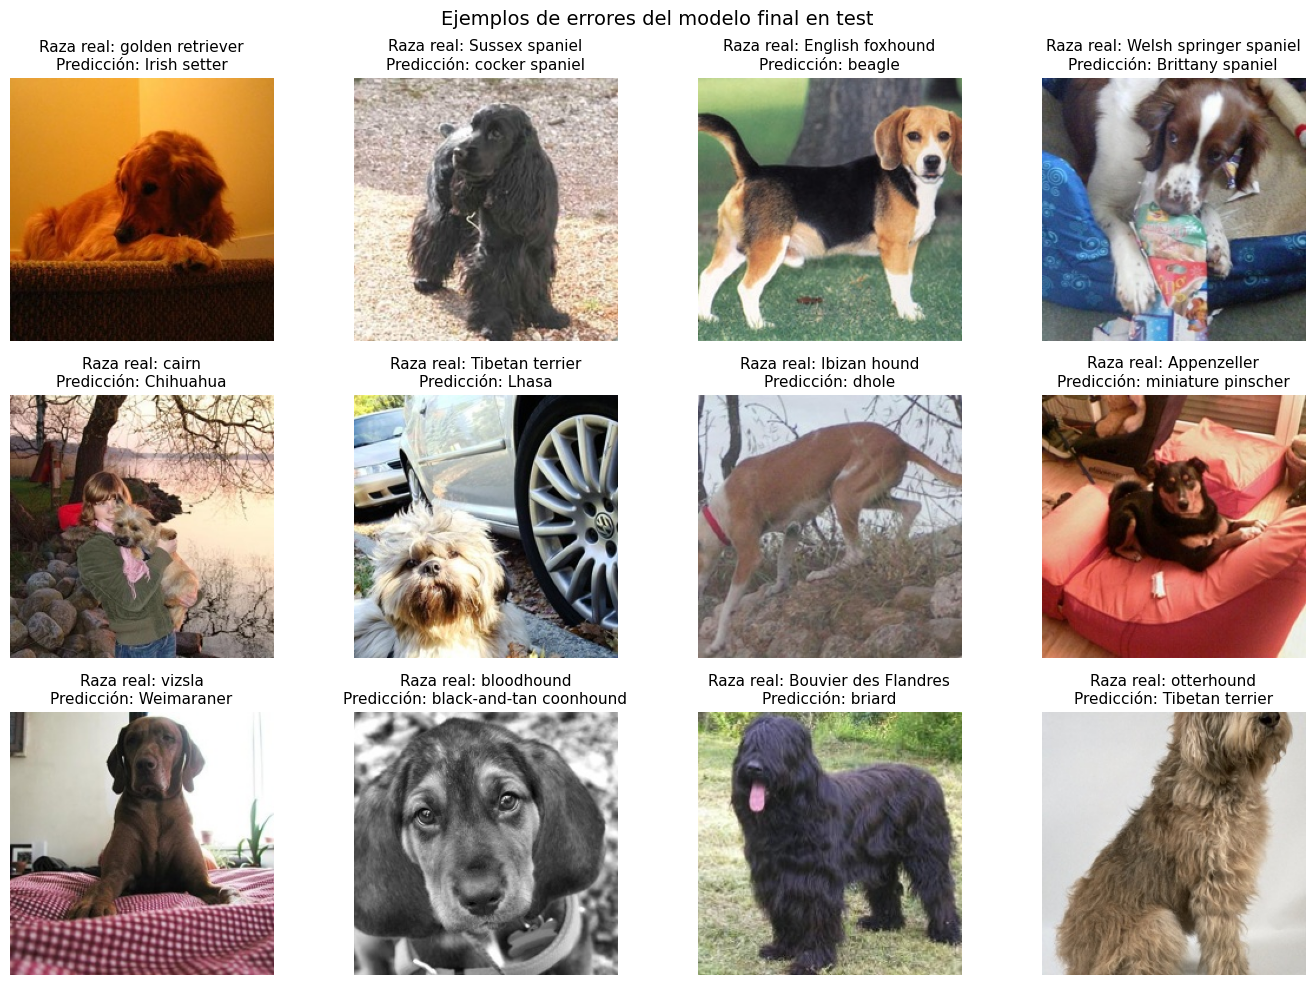

In [ ]:
errores = np.where(y_pred != y_real)[0]
muestra = np.random.default_rng(SEED).choice(errores, 12, replace=False)
mostrar_cuadricula(
    [test_df["ruta"].iloc[i] for i in muestra],
    [f"Raza real: {clases[y_real[i]]}\nPredicción: {clases[y_pred[i]]}" for i in muestra],
    "Ejemplos de errores del modelo final en test")

Por pérdida de validación, el modelo final es el fine-tuning del último bloque con tasa 1e-5, que obtiene en test un **87,3 % de accuracy y un 99,1 % de top-5 accuracy**. Acierta la raza en casi 9 de cada 10 imágenes que no ha visto nunca, y la raza correcta está entre sus 5 primeras opciones en el 99 % de los casos. Como referencia, un clasificador aleatorio acertaría el 0,8 % y uno que predijera siempre la raza más frecuente, el 1,2 %.

Los resultados en test son prácticamente iguales que en validación, así que las decisiones tomadas con el conjunto de validación no lo han sobreajustado. El clasificador sin fine-tuning y las dos variantes con tasa 1e-5 quedan también en test a menos de 0,2 puntos entre sí (del 87,2 % al 87,3 %), lo que confirma que el fine-tuning no aporta una mejora apreciable, y la variante con tasa 1e-4 vuelve a ser la peor (85,7 %).

Los errores no son aleatorios, sino que se concentran en grupos de razas muy parecidas:

* **Perros nórdicos**: el par más confundido es Eskimo dog con Siberian husky (7 imágenes), y el husky también se confunde con el malamute. Eskimo dog y Siberian husky están entre las tres razas con peor F1.
* **Razas que se distinguen sobre todo por el tamaño**: schnauzer estándar y gigante, y caniche toy, miniatura y estándar. En una foto sin referencias de escala el tamaño del perro no se puede apreciar, así que para la red son prácticamente la misma raza.
* **Razas casi idénticas a simple vista**, como collie y border collie, o Australian terrier y silky terrier.

En los ejemplos de errores se repite lo mismo: la mayoría son razas parecidas, como golden retriever e Irish setter, Sussex y cocker spaniel, English foxhound y beagle o vizsla y Weimaraner. En otros es la foto la que lo pone difícil: el perro sale pequeño y en brazos de una persona (cairn), tumbado y con poca luz (Appenzeller) o en blanco y negro, sin el color que distingue al bloodhound del black-and-tan coonhound. En el Ibizan hound, el recorte central ha dejado la cabeza fuera de la imagen, uno de los casos que ya anticipamos en la sección 3.

### 5.7. Conclusiones de la Estrategia 2

* Con redes preentrenadas en ImageNet se obtiene un **87,3 % de accuracy en test** (99,1 % en top-5) con muy poco coste. Casi todo ese rendimiento se consigue ya con la base congelada y un clasificador de una sola capa, que se entrena en segundos sobre las características precalculadas.
* **La arquitectura importa más que el tamaño**: MobileNetV2 y EfficientNetB0, con 2,3 y 4 millones de parámetros, superan en unos 4 puntos a ResNet50, que tiene 23,6 millones.
* **El preprocesado tiene más efecto que cualquier ajuste del modelo.** Recortar el centro en lugar de redimensionar aporta 4,4 puntos, y guardar las imágenes en JPEG con calidad 75 en lugar de 95 costaba 2. En cambio, el dropout y el fine-tuning con tasa baja mueven el resultado menos de 1 punto.
* **El fine-tuning apenas mejora**, y con una tasa de aprendizaje demasiado alta empeora. Lo atribuimos a que las 120 razas ya son clases de ImageNet, de modo que las características preentrenadas ya están prácticamente adaptadas a este problema.
* Ese mismo hecho obliga a interpretar los resultados con cautela. Las redes se preentrenaron con imágenes de ImageNet y es probable que algunas de nuestras imágenes de test estuvieran entre ellas, así que el 87,3 % es seguramente optimista respecto al rendimiento con fotos de perros completamente nuevas. Es una ventaja de partida que la Estrategia 1, entrenada desde cero, no tiene, y hay que tenerla en cuenta al comparar las dos estrategias en la sección 6.
* Los errores que quedan se concentran en razas muy parecidas o que solo se diferencian por el tamaño, donde la imagen por sí sola no da información suficiente para decidir.

## Exportación a PDF

El entregable se genera convirtiendo este notebook a PDF desde Colab. La celda solo se ejecuta al activar `EXPORTAR_PDF`, para que una ejecución completa del notebook no la lance.

In [ ]:
EXPORTAR_PDF = False

if EXPORTAR_PDF:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_FOLDER = "/content/drive/MyDrive/07MIAR_Proyecto_Programacion/"
    nombre_ipynb = "07MIAR_Proyecto_Programacion.ipynb"
    get_ipython().system(
        "apt-get update > /dev/null && apt-get install -y texlive-xetex texlive-fonts-recommended texlive-plain-generic > /dev/null")
    get_ipython().system(
        f"jupyter nbconvert --to pdf --output-dir='{BASE_FOLDER}' '{BASE_FOLDER}{nombre_ipynb}'")